# Лабораторная работа 4. Случайный лес

Цель эксперимента — сравнить sklearn и собственную реализацию на классификации переписчиков и оценке мощности волновой фермы. Все варианты оцениваются на одних и тех же объектах.

## Задачи и разбиение


**Avila** содержит десять признаков геометрии текстовых фрагментов латинской рукописи XII века. Классификация по переписчикам позволяет предварительно распределять фрагменты перед проверкой палеографом. Используется разбиение UCI. Номера страниц в признаках отсутствуют, поэтому результаты относятся к этому протоколу и одному манускрипту. [Источник и словарь признаков](https://doi.org/10.24432/C5K02X)

**Wave Energy Converters · Tasmania.** По координатам 16 преобразователей требуется оценить суммарную мощность фермы. Такой прогноз может ускорить отбор вариантов перед запуском гидродинамического симулятора. 16 индивидуальных мощностей исключены: их сумма практически равна целевой переменной. Разбиение учитывает группы конфигураций по координатам, округлённым до 10 м. Соседние конфигурации по разные стороны границы округления могут оказаться в разных частях. Данные охватывают один волновой сценарий. [Источник и схема данных](https://doi.org/10.24432/C5831S)

Обе задачи используют по три внутренних фолда. В каждом фолде масштабирование и модель подгоняются только по его обучающей части. Holdout одинаков для всех пяти работ и используется после выбора конфигураций.

In [1]:
# Загружаем фиксированные разбиения и общие функции эксперимента.
import pandas as pd
from IPython.display import Markdown, display
from labkit.data import load_tasks
from labkit.experiments import (
    comparison_text, describe_data, evaluate_holdout, plot_predictions,
    plot_training, primary_metric, save_scores, select_candidates,
)

LAB = 4
tasks = load_tasks()
display(describe_data(tasks))
for task in tasks:
    display(pd.Series(task.audit, name=task.title).to_frame())

,задача,строк в исходных файлах,train,test,исходные признаки,разбиение
0,Avila — автор фрагмента,20867,10430,10437,10,Официальные train/test; 3 стратифицированных ф...
1,Tasmania — суммарная мощность (МВт),72000,5762,1438,32,Групповой holdout 20% групп; 3 групповых фолда...


,Avila — автор фрагмента
Точных совпадений векторов признаков между train/test,0


,Tasmania — суммарная мощность (МВт)
Строк после проверки диапазонов и пропусков,72000
Точных уникальных конфигураций,72000
Строк в воспроизводимой подвыборке,7200
Групп в подвыборке (округление координат до 10 м),7183


## Выбор метрик


**Avila.** Macro-F1 усредняет F1 по всем 12 классам, сохраняя вклад редких переписчиков. Balanced accuracy — средняя полнота по классам. Accuracy показывает долю верных ответов по всем фрагментам.

**Tasmania.** MAE в МВт показывает средний абсолютный промах. RMSE в тех же единицах сильнее учитывает большие ошибки. R² отражает долю объяснённой вариации относительно среднего отклика теста и может быть отрицательным.

Для проверки полезности моделей используется простой ориентир. Классификационный dummy всегда выбирает самый частый класс train, регрессионный — медиану train. Основные метрики для выбора конфигурации — macro-F1 (выше) и MAE (ниже).

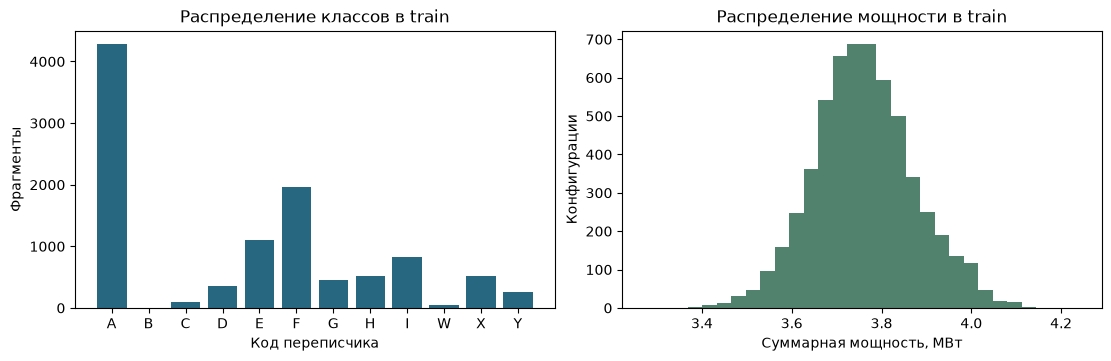

In [2]:
# Изучаем дисбаланс классов и масштаб мощности на обучающих данных.
plot_training(tasks)

## Библиотечный бейзлайн

RandomForestClassifier и RandomForestRegressor обучают 32 дерева на bootstrap-выборках. В каждом узле рассматривается случайное подмножество примерно из квадратного корня числа признаков. Бюджет в 32 дерева задан и библиотечному, и собственному бейзлайну.

## Гипотезы и кросс-валидация

Проверяем, помогает ли увеличение числа деревьев до 64 уменьшить дисперсию ансамбля. Для Avila также проверяются балансировка классов и ограничения сложности деревьев. Для Tasmania сравниваем координаты, геометрию и их объединение. Геометрические признаки могут повысить информативность небольшого случайного подмножества в узле.

В сетку включён бейзлайн. При равенстве средних метрик приоритет получает первая конфигурация. В таблицах приведены оценки каждого фолда и стандартное отклонение между фолдами.

In [3]:
# Проверяем гипотезы на трёх внутренних фолдах и фиксируем победителей.
selections = select_candidates(LAB, tasks)
for task in tasks:
    display(Markdown(f"**{task.title} · {primary_metric(task)}**"))
    display(selections[task.key][2].round(5))

**Avila — автор фрагмента · macro_f1**

,гипотеза,признаки,настройки,CV среднее,CV σ,фолд 1,фолд 2,фолд 3,выбран
0,Бейзлайн,raw,{},0.96474,0.01498,0.94785,0.97000,0.97638,False
1,Взвешивание редких классов,raw,"{""class_weight"": ""balanced""}",0.96310,0.02095,0.96389,0.94177,0.98364,False
2,Глубина 14 и минимум 3 в листе,raw,"{""max_depth"": 14, ""min_samples_leaf"": 3}",0.89762,0.04588,0.84820,0.90581,0.93885,False
3,64 дерева,raw,"{""n_estimators"": 64}",0.97191,0.01056,0.96177,0.97112,0.98284,True


**Tasmania — суммарная мощность (МВт) · mae_mw**

,гипотеза,признаки,настройки,CV среднее,CV σ,фолд 1,фолд 2,фолд 3,выбран
0,Бейзлайн,raw,{},0.05162,0.00030,0.05197,0.05143,0.05147,False
1,Геометрия,geometry,{},0.04974,0.00098,0.04993,0.05062,0.04867,False
2,64 дерева,raw,"{""n_estimators"": 64}",0.05098,0.00064,0.05151,0.05028,0.05117,False
3,Геометрия и ограничения деревьев,geometry,"{""max_depth"": 14, ""min_samples_leaf"": 3}",0.04976,0.00097,0.04980,0.05071,0.04877,False
4,Координаты и геометрия,combined,{},0.04759,0.00058,0.04797,0.04787,0.04693,True


## Оценка sklearn на отложенной выборке

Переобучаем бейзлайн и победителя CV на всём train. В итоговом сравнении сохраняем фактический результат даже при снижении качества на holdout.

In [4]:
# Получаем holdout-метрики и сохраняем прогнозы для анализа ошибок.
results = evaluate_holdout(LAB, tasks, selections)
for task in tasks:
    table, _ = results[task.key]
    base = table.loc[table["version"].isin(["dummy", "sklearn baseline", "sklearn tuned"])]
    display(Markdown(f"**{task.title}**"))
    display(base.dropna(axis=1, how="all").drop(columns=["lab", "task", "algorithm"]).round(5))

**Avila — автор фрагмента**

,version,candidate,fit_s,predict_s,macro_f1,balanced_accuracy,accuracy
0,dummy,Мода,NaN,NaN,0.04852,0.08333,0.41065
1,sklearn baseline,Бейзлайн,0.85216,0.06733,0.98152,0.97484,0.98285
2,sklearn tuned,64 дерева,1.57463,0.15845,0.98705,0.98325,0.98659


**Tasmania — суммарная мощность (МВт)**

,version,candidate,fit_s,predict_s,mae_mw,rmse_mw,r2
0,dummy,Медиана,NaN,NaN,0.08752,0.11228,-0.00000
1,sklearn baseline,Бейзлайн,0.84958,0.01643,0.05184,0.06984,0.61304
2,sklearn tuned,Координаты и геометрия,1.13579,0.06147,0.04620,0.06304,0.68479


## Собственная реализация

BootstrapForest генерирует индексы с возвращением отдельно для каждого собственного CART. Признаки заново случайно выбираются в каждом узле. Для классификации усредняются распределения классов по листьям, для регрессии — прогнозы деревьев. В общей шкале вероятностей сохраняются позиции классов, которые могли отсутствовать в конкретной bootstrap-выборке. Различие генераторов и порогов меняет конкретные деревья при одном seed.

Параметры и преобразования переносятся из библиотечного бейзлайна и лучшей библиотечной конфигурации соответственно. Повторного подбора по holdout нет. [Код оценивателей](labkit/models.py)

In [5]:
# Сопоставляем две собственные версии с эквивалентными конфигурациями sklearn.
for task in tasks:
    table, _ = results[task.key]
    models = table.loc[table["version"] != "dummy"]
    display(Markdown(f"**{task.title}**"))
    display(models.dropna(axis=1, how="all").drop(columns=["lab", "task", "algorithm"]).round(5))

**Avila — автор фрагмента**

,version,candidate,fit_s,predict_s,macro_f1,balanced_accuracy,accuracy
1,sklearn baseline,Бейзлайн,0.85216,0.06733,0.98152,0.97484,0.98285
2,sklearn tuned,64 дерева,1.57463,0.15845,0.98705,0.98325,0.98659
3,own baseline,Бейзлайн,3.31992,0.17745,0.98058,0.97307,0.98007
4,own tuned,64 дерева,6.01569,0.21700,0.98378,0.97867,0.98256


**Tasmania — суммарная мощность (МВт)**

,version,candidate,fit_s,predict_s,mae_mw,rmse_mw,r2
1,sklearn baseline,Бейзлайн,0.84958,0.01643,0.05184,0.06984,0.61304
2,sklearn tuned,Координаты и геометрия,1.13579,0.06147,0.04620,0.06304,0.68479
3,own baseline,Бейзлайн,7.69250,0.02768,0.05239,0.07102,0.59992
4,own tuned,Координаты и геометрия,8.55298,0.05387,0.04633,0.06338,0.68137


## Диагностика ошибок

Матрица ошибок нормирована по истинному классу. Точки на графике мощности сравниваются с диагональю идеального прогноза. Обе визуализации относятся к варианту sklearn, выбранному по CV.

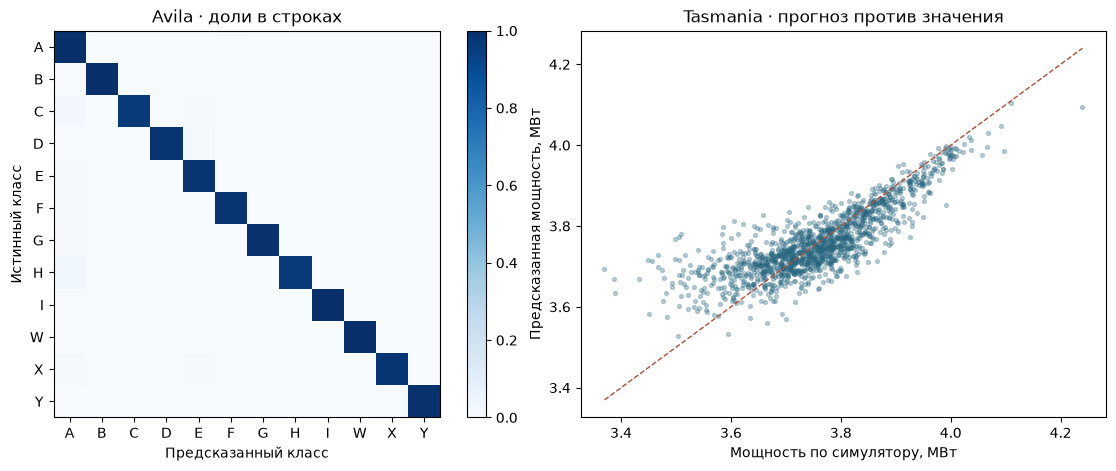

In [6]:
# Визуализируем ошибки классификации и отклонения мощности на holdout.
plot_predictions(tasks, results)

## Выводы

In [7]:
# Формируем вывод из измеренных метрик и экспортируем входные данные для сводки.
display(Markdown(comparison_text(tasks, results, selections)))
relative_path = save_scores(LAB, results)
print(f"Метрики сохранены в {relative_path.as_posix()}")

**Avila — автор фрагмента.** По CV выбран вариант «64 дерева» (macro-F1 0.9719, бейзлайн 0.9647). На holdout macro-F1 sklearn улучшился относительно бейзлайна: 0.9815 → 0.9870. Собственная реализация: 0.9806 → 0.9838. Разница собственной модели и sklearn macro-F1: -0.0009 в бейзлайне, -0.0033 после настройки.

**Tasmania — суммарная мощность (МВт).** По CV выбран вариант «Координаты и геометрия» (MAE 0.0476 МВт, бейзлайн 0.0516 МВт). На holdout MAE sklearn улучшился относительно бейзлайна: 0.0518 → 0.0462 МВт. Собственная реализация: 0.0524 → 0.0463 МВт. Разница собственной модели и sklearn MAE: +0.0005 МВт в бейзлайне, +0.0001 МВт после настройки.

Метрики сохранены в results/lab_04.csv
